In [ ]:
def metrics(y_true, y_pred):
    """Common regression skill scores for continuous targets (MAR or TOC).

    mae  — mean absolute error (same units as the target; lower is better)
    corr — Pearson correlation between observations and predictions
    r2   — coefficient of determination (1 = perfect; can be negative)
    """
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "corr": float(np.corrcoef(y_true.ravel(), y_pred.ravel())[0, 1]),
        "r2": float(r2_score(y_true, y_pred)),
    }


def plot_pred_scatter(y_train, train_pred, y_test, test_pred, title):
    """Observed vs predicted scatter for train (grey) and test (coloured) sites.

    The dashed line is the 1:1 relation: predictions that fall near it are accurate.
    """
    tr = metrics(y_train, train_pred)
    te = metrics(y_test, test_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_train, train_pred, s=8, alpha=0.35, label=f"train MAE={tr['mae']:.2f}, r={tr['corr']:.3f}")
    ax.scatter(y_test, test_pred, s=8, alpha=0.45, label=f"test MAE={te['mae']:.2f}, r={te['corr']:.3f}")
    lims = [
        min(y_train.min(), y_test.min(), train_pred.min(), test_pred.min()),
        max(y_train.max(), y_test.max(), train_pred.max(), test_pred.max()),
    ]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()
    return tr, te


## Load paired MAR and TOC observations (attention features)

We train one network on two related sediment properties at the same locations:

- **MAR** — mass accumulation rate (g cm⁻² kyr⁻¹), the primary prediction target
- **TOC** — total organic carbon (wt%), used as an auxiliary task that shares representation with MAR

**Feature design.** Each sample is a 226-dimensional vector: 113 environmental predictors (values) plus 113 binary **presence/absence masks** that mark which predictors were originally missing before neural-network imputation. The attention encoder uses both channels so the model can learn which inputs are observed versus imputed.


In [1]:
# Load CS + DO cores for both tasks. The "attention" loaders return
# value+mask features (226 columns) and a stratified 75/25 train–test split
# by MAR deciles so high- and low-MAR regimes are represented in both sets.
mar = load_mar_cs_do_attention()
toc = load_toc_cs_do_attention()

# MAR (sedimentation / mass-accumulation) matrices
sedrate_train_features = mar["train_features"]   # predictors used for fitting
sedrate_train_labels = mar["train_labels"]       # observed MAR at train sites
sedrate_test_features = mar["test_features"]     # held-out predictors
sedrate_test_labels = mar["test_labels"]         # held-out MAR (for skill scores)
sedrate_features = mar["features"]               # all sites (used to size the network)

# TOC matrices — same geographic sites, different response variable
toc_train_features = toc["train_features"]
toc_train_labels = toc["train_labels"]
toc_test_features = toc["test_features"]
toc_test_labels = toc["test_labels"]

# Standardization stats from the training features (applied later to world grids)
X_mean, X_std = mar["x_mean"], mar["x_std"]
world_dir = mar["world_dir"]           # folder of global ocean feature chunks
n_value_features = mar["n_value_features"]  # 113 value channels (masks follow)

print("MAR train/test:", sedrate_train_features.shape, sedrate_test_features.shape)
print("TOC train/test:", toc_train_features.shape, toc_test_features.shape)
print("n_features:", mar["n_features"])
assert mar["n_features"] == 226, mar["n_features"]


n_features=226 (NN-imputed values+masks)
train=(9860, 226), test=(3288, 226)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Mini-batch iterators and loss function

Neural-network training proceeds in **mini-batches**: small random subsets of
sites are shown to the model in each step. `DataLoader` objects wrap the
feature/label arrays and feed those batches to the optimizer.

We keep separate loaders for the MAR and TOC tasks so the multi-task trainer
can alternate updates on both heads. The objective is **Huber loss**, which
behaves like squared error for small residuals and like absolute error for
large residuals — useful when MAR has heavy-tailed outliers.


In [ ]:
# Number of sites shown to the network in one optimization step
batch_size = 32

# Training loaders: shuffle=True randomizes site order each epoch so the
# optimizer does not memorize a fixed sequence.
train_dataloaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(
            torch.tensor(sedrate_train_features, dtype=torch.float32),
            torch.tensor(sedrate_train_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=True,
    ),
    "toc": DataLoader(
        TensorDataset(
            torch.tensor(toc_train_features, dtype=torch.float32),
            torch.tensor(toc_train_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=True,
    ),
}

# Test loaders: shuffle=False keeps evaluation deterministic and reproducible
test_dataloaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(
            torch.tensor(sedrate_test_features, dtype=torch.float32),
            torch.tensor(sedrate_test_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=False,
    ),
    "toc": DataLoader(
        TensorDataset(
            torch.tensor(toc_test_features, dtype=torch.float32),
            torch.tensor(toc_test_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=False,
    ),
}

# Robust regression loss (less sensitive to extreme MAR outliers than MSE alone)
loss_fn = torch.nn.HuberLoss()


## Fit the multi-task attention network

This cell builds and trains a **multi-task learning (MTL)** model with a
**feature-token attention** encoder:

1. Each of the 113 predictors is treated as a token that carries its value and
   its missingness mask.
2. Self-attention mixes information across predictors (which variables matter
   together for a given site).
3. Shared layers produce a joint representation; two task heads then predict
   **MAR** and **TOC** from that representation.

Hyperparameters below were selected by a held-out hyperparameter search
(embedding dimension 128, 8 attention heads, 2 transformer layers, feed-forward
width multiplier 2, dropout 0.2). Training uses Adam with early stopping on the
validation MAR loss; the learning curves plotted at the end show whether the
fit is stable or overfits.


Training MTL attention config attn_d128_h8_l2_ff2_do0.2: {'d_model': 128, 'n_heads': 8, 'n_layers': 2, 'ff_mult': 2, 'dropout': 0.2}
epoch: 0 | Training Loss (sedimentation_rates): 116.24712 | lr: 1.00e-04
epoch: 0 | Training Loss (toc): 0.27645
epoch: 1 | Training Loss (sedimentation_rates): 101.01691 | lr: 1.00e-04
epoch: 1 | Training Loss (toc): 0.26347
epoch: 2 | Training Loss (sedimentation_rates): 78.14247 | lr: 1.00e-04
epoch: 2 | Training Loss (toc): 0.27963
epoch: 3 | Training Loss (sedimentation_rates): 72.65931 | lr: 1.00e-04
epoch: 3 | Training Loss (toc): 0.25351
epoch: 4 | Training Loss (sedimentation_rates): 68.58840 | lr: 1.00e-04
epoch: 4 | Training Loss (toc): 0.24407
epoch: 5 | Training Loss (sedimentation_rates): 67.84995 | lr: 1.00e-04
epoch: 5 | Training Loss (toc): 0.24133
epoch: 6 | Training Loss (sedimentation_rates): 66.94094 | lr: 1.00e-04
epoch: 6 | Training Loss (toc): 0.24381
epoch: 7 | Training Loss (sedimentation_rates): 67.68012 | lr: 1.00e-04
epoch: 7 

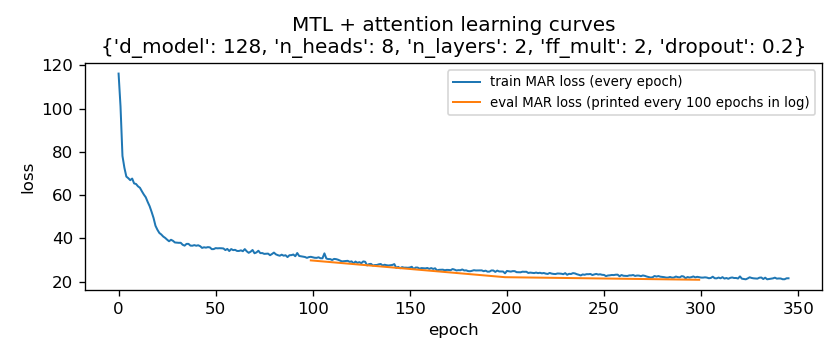

In [2]:
# Architecture chosen by hyperparameter search (held-out MAR skill):
#   d_model  — width of each feature token after embedding
#   n_heads  — parallel attention heads (must divide d_model)
#   n_layers — stacked self-attention + feed-forward blocks
#   ff_mult  — hidden width of the feed-forward block = ff_mult * d_model
#   dropout  — fraction of units randomly dropped during training (regularization)
attn_cfg = dict(d_model=128, n_heads=8, n_layers=2, ff_mult=2, dropout=0.2)
num_epochs = 2000  # upper bound; early stopping usually ends sooner

train_step = 2     # alternate MAR / TOC updates inside the multi-task trainer
write_maps = True  # if True, later cell writes global ocean prediction grids

# Fix random seeds so weight initialization (and thus the fit) is reproducible
set_seed(42)

# Construct the MTL attention network. n_value_features tells the encoder how
# many leading columns are continuous values; the remaining columns are masks.
model = buildAttentionMTL(
    sedrate_features,
    n_value_features=n_value_features,
    **attn_cfg,
)
model.double()  # float64 — matches the numerical precision used in the search

# Optimize network weights. Returns per-epoch training / evaluation losses
# (dicts keyed by task name) and the learning-rate schedule.
training_losses, learning_rate, evaluation_losses = train_model(
    model,
    loss_fn,
    train_dataloaders,
    test_dataloaders,
    train_step=train_step,
    num_epochs=num_epochs,
)

# Directory for weights, scatter summaries, and prediction maps from this run
out_dir = PREDICTION_MAPS_DIR / "notebooks_mtl_attention"
out_dir.mkdir(parents=True, exist_ok=True)

# Helper: pull the MAR entry out of a multi-task loss dict for plotting
def _sed_loss(x):
    return x["sedimentation_rates"] if isinstance(x, dict) else float(x)

# Learning curves: how the MAR loss changes over epochs.
# Falling train+eval curves → the fit is improving; a rising eval curve
# while train keeps falling would indicate overfitting.
train_curve = [_sed_loss(v) for v in training_losses]
eval_curve = [_sed_loss(v) for v in evaluation_losses]

plt.figure(figsize=(7, 3))
plt.plot(train_curve, label="train MAR loss")
plt.plot(eval_curve, label="eval MAR loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title(f"MTL + attention learning curves\n{attn_cfg}")
plt.tight_layout()
plt.show()  # figure is shown below this cell


## Evaluate predictive skill and map global fields

With the fitted network we:

1. Score **train** and **test** sites for both MAR and TOC (MAE, correlation, $R^2$).
2. Draw observed-vs-predicted scatter plots — points near the 1:1 line indicate good skill.
3. Save network weights for reuse.
4. Optionally apply the model to the global ocean feature grid (in geographic chunks)
   to produce continuous MAR and TOC prediction maps, with land cells zeroed using
   an island mask.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


=== Test metrics ===
sedimentation_rates: MAE=20.2881 MSE=6484.1911 R2=0.8363 corr=0.9147
toc: MAE=0.3958 MSE=0.8531 R2=0.3792 corr=0.6225
  world prediction 60/360
  world prediction 120/360
  world prediction 180/360
  world prediction 240/360
  world prediction 300/360
  world prediction 360/360
Saved prediction_map_MAR_entire_MTL_n_attention_attn_d128_h8_l2_ff2_do0.2.npy and prediction_map_toc_entire_MTL_n_attention_attn_d128_h8_l2_ff2_do0.2.npy


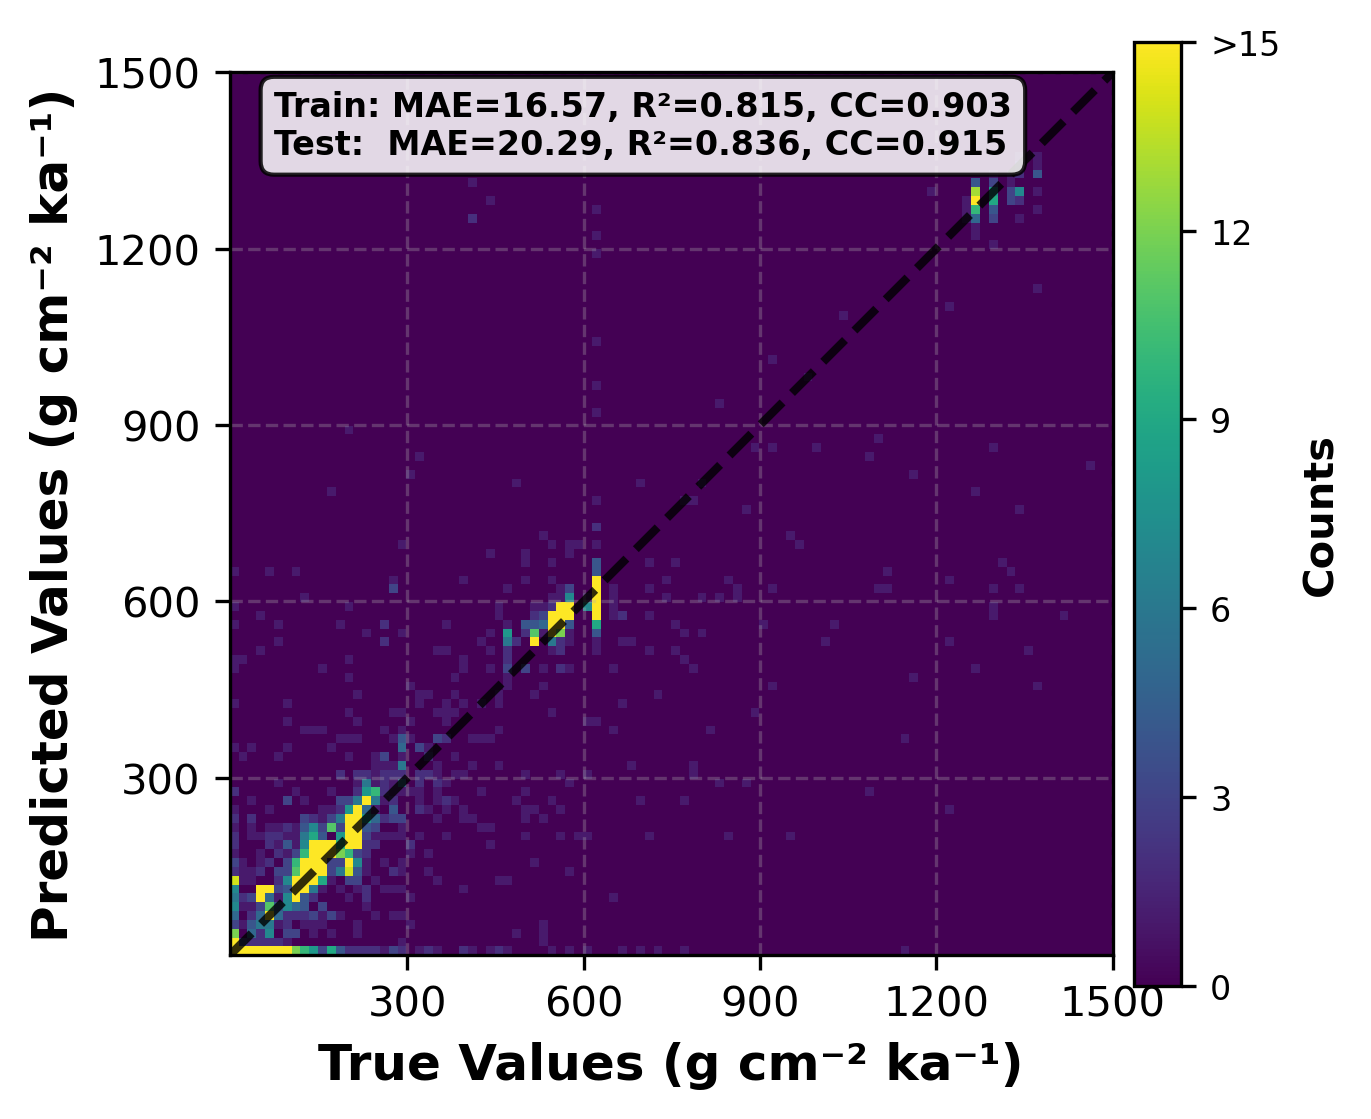

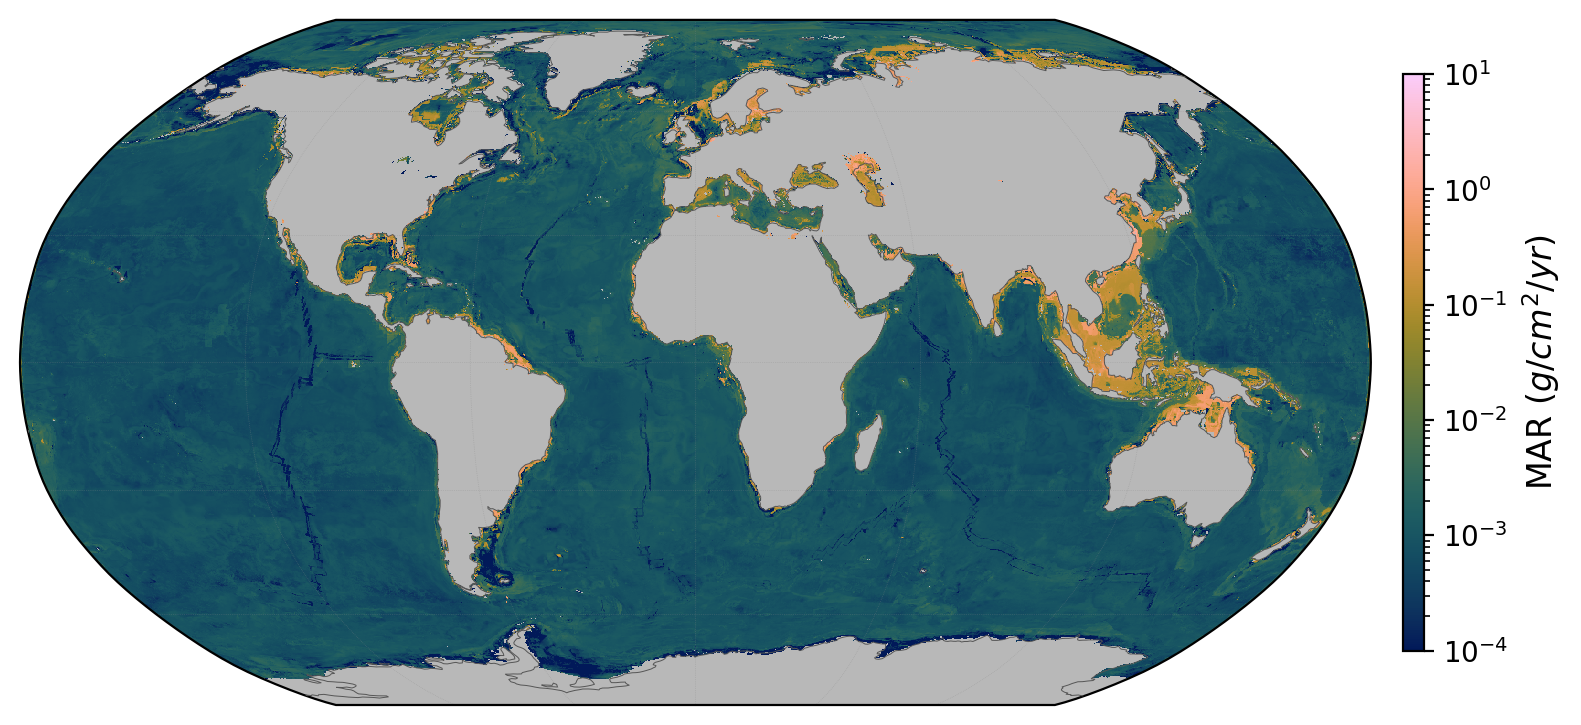

In [3]:
# --- helpers -----------------------------------------------------------------

def collect_task_predictions(model, loader, task):
    """Run the network on every batch in `loader` and collect labels + predictions.

    `task` selects which head to read: "sedimentation_rates" (MAR) or "toc".
    `torch.no_grad()` disables gradient tracking — evaluation does not update weights.
    """
    model.eval()  # turn off dropout; use running statistics for any BatchNorm layers
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=torch.float64)
            # model returns (decoded_features, task_prediction); we keep the prediction
            _decoded, out = model(x, task_id=task)
            ys.append(y.numpy().reshape(-1))
            ps.append(out.detach().cpu().numpy().reshape(-1))
    return np.concatenate(ys), np.concatenate(ps)


# --- skill scores + scatter plots for both tasks -----------------------------

rows = []
for task, label in [("sedimentation_rates", "MAR"), ("toc", "TOC")]:
    y_tr, p_tr = collect_task_predictions(model, train_dataloaders[task], task)
    y_te, p_te = collect_task_predictions(model, test_dataloaders[task], task)
    tr, te = plot_pred_scatter(y_tr, p_tr, y_te, p_te, f"MTL + attention — {label}")
    rows.append({"task": label, **{f"test_{k}": v for k, v in te.items()}})

# Persist test metrics as a small CSV for tables / downstream scripts
pd.DataFrame(rows).to_csv(out_dir / "mtl_attention_test_summary.csv", index=False)

# Encode architecture in the filename so different search configs do not overwrite
tag = (
    f"attn_d{attn_cfg['d_model']}_h{attn_cfg['n_heads']}"
    f"_l{attn_cfg['n_layers']}_ff{attn_cfg['ff_mult']}_do{attn_cfg['dropout']}"
)
weight_path = out_dir / f"model_MTL_attention_{tag}_nnimputed.pt"
torch.save(model.state_dict(), weight_path)
print("Saved weights:", weight_path)


# --- optional: global ocean prediction maps ----------------------------------
# World features are stored as many small .npy "chunks" (rows of a global grid).
# We predict each chunk, stitch them into full maps, then mask land.

if write_maps:
    chunk_shape = (6, 4320)  # spatial layout of one stored world-feature file
    files = sorted(p for p in world_dir.iterdir() if p.suffix == ".npy")
    map_mar = map_toc = None
    model.eval()
    with torch.no_grad():
        for i, f in enumerate(files):
            # Standardize with the same mean/std used at training time
            feats = normalize_world_chunk_attention(np.load(f), X_mean, X_std)
            t = torch.tensor(feats, dtype=torch.float64, device=device)
            _, p_mar = model(t, task_id="sedimentation_rates")
            _, p_toc = model(t, task_id="toc")
            p_mar = p_mar.detach().cpu().numpy().reshape(chunk_shape)
            p_toc = p_toc.detach().cpu().numpy().reshape(chunk_shape)
            # Grow the maps by appending chunks along the latitude axis
            map_mar = p_mar if map_mar is None else np.append(map_mar, p_mar, axis=0)
            map_toc = p_toc if map_toc is None else np.append(map_toc, p_toc, axis=0)
            if (i + 1) % 60 == 0:
                print(f"  predicted {i+1}/{len(files)} chunks")
            del t, feats
            gc.collect()  # free GPU/CPU memory between chunks

    # Align map orientation with the land mask, then zero continental cells
    land = np.load(DATA_RAW / "island_map.npy")
    land = np.where(np.isnan(land), 1, land).astype(bool)
    for arr, name in [(map_mar, "MAR"), (map_toc, "toc")]:
        arr = np.rot90(np.rot90(np.fliplr(arr)))
        arr[land] = 0
        path = out_dir / f"prediction_map_{name}_entire_MTL_attention_{tag}.npy"
        np.save(path, arr)
        print("Saved:", path)
